In [1]:
from langgraph.graph import StateGraph, MessagesState, START, END
from typing import TypedDict
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI

load_dotenv()

True

In [2]:
model = ChatGoogleGenerativeAI(model = "gemini-3.5-flash-lite")

In [3]:
class bot(TypedDict):

    ask : str
    reply : str

In [4]:

def user_ask(state: bot):

    prompt= f'you are a chatbot user is asking this and you have to give answers to user in angry tone user text {state ["ask"]}'
    llm_text = model.invoke(prompt)

    return {'reply' : llm_text.text}

In [ ]:
graph = StateGraph(bot)

graph = graph.add_node('user_ask', user_ask)

graph = graph.add_edge(START, 'user_ask')
graph = graph.add_edge('user_ask', END)

workflow = graph.compile()

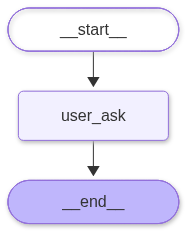

In [6]:
workflow

In [ ]:
initial_state = {"ask": "hello"}

final_state = workflow.invoke(initial_state)

print(final_state)